# Part 3: Chunked prefill (Sarathi)

Fill the Part 3 TODOs in `vidur/scheduler/replica_scheduler/sarathi_replica_scheduler.py` first (`pytest tests/test_sarathi_chunk.py`, `pytest tests/test_sarathi_batch.py`). Then run Sarathi at three token budgets from the repo root:

```bash
for C in 256 512 2048; do
  SCHED=sarathi CHUNK=$C QPS=5.53 bash scripts/run_default.sh traces/azure_conversation.csv
done
```

Runs go one after another, about 3 minutes each. If you have plenty of RAM, you can run them in the background instead (add `&` after each command, then `wait`), but each run needs a few GB: four at once ran out of memory on a 16 GB laptop.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd()
if not (ROOT / "traces").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from analysis.replay import describe_run, load_run
from analysis.workload import load_trace

WAIT_TARGET_S = 2.0    # P99 wait under 2 s
TBT_TARGET_S = 0.100   # P99 time between tokens under 100 ms

trace = load_trace(ROOT / "traces" / "azure_conversation.csv")

# Your Part 2 vLLM run and your three Sarathi runs, any order.
RUN_DIRS = [ROOT / "simulator_output" / d for d in [
    "2026-10-25_23-06-57-910635",   # Part 2: vLLM
    "2026-10-27_09-32-40-989693",   # Sarathi C = 256
    "2026-10-27_09-32-07-174520",   # Sarathi C = 512
    "2026-10-27_09-33-15-163902",   # Sarathi C = 2048
]]
runs = {describe_run(d): load_run(d, trace) for d in RUN_DIRS}
print(list(runs))

['vllm', 'sarathi C=256', 'sarathi C=512', 'sarathi C=2048']


## Predicted vs measured

Type your Part 2 Q4 predictions for the P99 time between tokens (in ms) into `PREDICTED_TBT_P99_MS` below. In the table, TBT is the time between tokens and TTFT the time to first token.

In [ ]:
PREDICTED_TBT_P99_MS = {256: 26.0, 512: 45.9, 2048: 165.7} 

print(f"{'run':16s}{'predicted':>11s}{'P99 TBT':>11s}{'longest':>11s}{'P99 wait':>11s}{'wait > 2 s':>12s}{'median TTFT':>13s}")
for name, run in runs.items():
    tbt = run["tbt"].set_index("percentile").seconds
    wait = run["requests"].wait
    c = int(name.split("C=")[1]) if "C=" in name else None
    pred = PREDICTED_TBT_P99_MS.get(c) if c else None
    pred_s = f"{pred:.1f} ms" if pred else "-"
    print(f"{name:16s}{pred_s:>11s}{tbt[99]*1e3:8.0f} ms{tbt[100]*1e3:8.0f} ms{wait.quantile(.99):9.1f} s{np.mean(wait > WAIT_TARGET_S):12.0%}{run['requests'].ttft.median():11.2f} s")

run               predicted    P99 TBT    longest   P99 wait  wait > 2 s  median TTFT
vllm                      -     563 ms    6626 ms    128.8 s         41%       0.40 s
sarathi C=256       26.0 ms      37 ms      40 ms    293.2 s         83%     100.82 s
sarathi C=512       45.9 ms      62 ms      66 ms    171.2 s         52%       9.08 s
sarathi C=2048     165.7 ms     205 ms     214 ms    108.4 s         37%       0.43 s


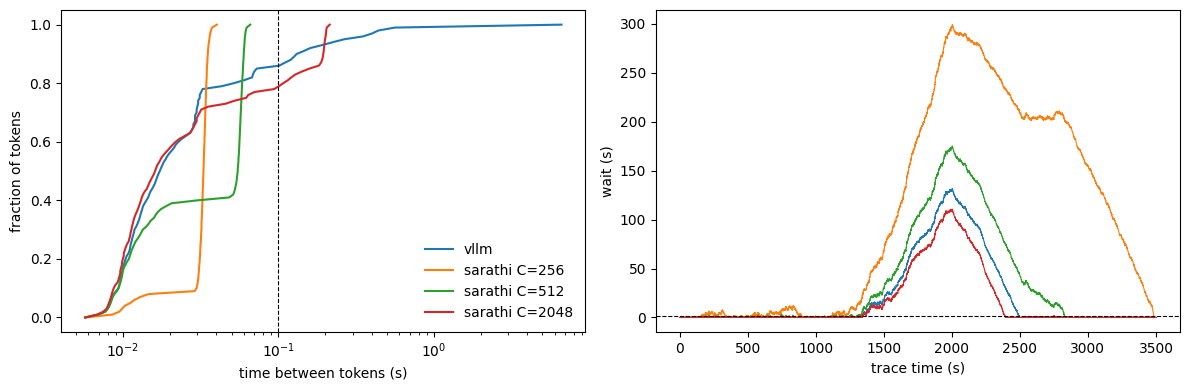

In [3]:
fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(12, 4))
for name, run in runs.items():
    tbt = run["tbt"]
    ax0.plot(tbt.seconds, tbt.percentile / 100, label=name)
    req = run["requests"]
    ax1.plot(req.arrived_at, req.wait, label=name, linewidth=0.8)
ax0.axvline(TBT_TARGET_S, color="k", linestyle="--", linewidth=0.8)
ax0.set_xscale("log")
ax0.set_xlabel("time between tokens (s)")
ax0.set_ylabel("fraction of tokens")
ax0.legend(frameon=False)
ax1.axhline(WAIT_TARGET_S, color="k", linestyle="--", linewidth=0.8)
ax1.set_xlabel("trace time (s)")
ax1.set_ylabel("wait (s)")
fig.tight_layout()
plt.show()

In [ ]:
# Numbers for Q2 and Q3: model throughput, per-pass time, and the best wait of any run
from analysis.workload import predict_queue_wait

def pass_time_model_ms(c):
    return 6 + c * 0.078

print("model vs actual pass times")

for d in RUN_DIRS:
    name = describe_run(d)

    if "C=" not in name:
        continue

    c = int(name.split("C=")[1])

    file = d / "plots" / "batch_execution_time.csv"
    bt = pd.read_csv(file)
    bt = bt.set_index("cdf")["batch_execution_time"]

    modelTime = pass_time_model_ms(c)
    tok_s = c / (modelTime / 1000)

    p99 = bt[0.99] * 1000
    p50 = bt[0.5] * 1000

    print("C =", c)
    print("model time", round(modelTime,1), "ms")
    print("tokens/s", round(tok_s))
    print("measured p99", round(p99,1), "p50", round(p50,1))
    print()

p99_waits = {}

for name in runs:
    reqs = runs[name]["requests"]
    w = reqs.wait.quantile(0.99)
    p99_waits[name] = w

for name, w in p99_waits.items():
    print(name, "p99 wait:", round(w,1), "s")

best = min(p99_waits, key=p99_waits.get)

print()
print("best wait was", best)
print("p99:", round(p99_waits[best],1))

pred = predict_queue_wait(trace)
p99_pred = np.quantile(pred, 0.99)

print("part 1 prediction:", round(p99_pred,1), "seconds")


     C  model pass  model tokens/s  measured P99 pass  measured P50 pass
   256     26.0 ms           9,858            37.2 ms            32.4 ms
   512     45.9 ms          11,146            61.5 ms            11.4 ms
  2048    165.7 ms          12,356           201.3 ms            10.0 ms

P99 wait  vllm             128.8 s
P99 wait  sarathi C=256    293.2 s
P99 wait  sarathi C=512    171.2 s
P99 wait  sarathi C=2048   108.4 s
lowest P99 wait across the runs: sarathi C=2048 at 108.4 s
Part 1 prediction, one GPU at full throughput: 72.1 s


## Questions

**Q1.** Fill in the table. Which budgets meet the 100 ms target?

| C | Predicted P99 time between tokens (Part 2 Q4) | Measured | Meets 100 ms? |
|---|---|---|---|
| 256 | 26.0 ms | 37 ms | yes |
| 512 | 45.9 ms | 62 ms | yes |
| 2048 | 165.7 ms | 205 ms | no |

**Your answer:**

**C = 256 and C = 512 satisfy the 100 ms requirement; C = 2048 doesn’t meet the requirement.** This is the result predicted in Part 2 Q4. In contrast to vLLM (P99 of 563 ms, maximum delay was 6.6 s), the maximum waiting time for Sarathi is only 40 ms (C = 256), 66 ms (C = 512), and 214 ms (C = 2048)—meaning that there are no more long halts.

The results we got exceeded my prediction by 24–42%. The model with time consumption of 6 ms + 78 µs per token is underestimated for the overall time measure; the measured P99 duration of passes equal to 37.2, 61.5, and 201.3 ms versus the predicted durations of 26.0, 45.9, and 165.7 ms, while the difference increases with the increase of C (about 11, 16, and 36 ms). The model is evidently fitted for simply the prefill time. Probably, the attention cost wasn’t taken into account: any pass embodies about 35–65 of running requests, which read their KV caches, and later parts of the long prompt attend to all processed data.

**Q2.** Each pass pays about 6 ms fixed plus 78 µs per token (the same model as Part 2 Q4), so throughput is C / (6 ms + C × 78 µs). Fill in the table, then pick the budget that meets the 100 ms target with the lowest P99 wait. In one sentence: why does a smaller C cost throughput?

| C | Model throughput (tokens/s) | Measured P99 wait | Median time to first token |
|---|---|---|---|
| 256 | 9,858 | 293.2 s | 100.82 s |
| 512 | 11,146 | 171.2 s | 9.08 s |
| 2048 | 12,356 | 108.4 s | 0.43 s |

**Your answer:**

The value of C=512 is the minimum delay but C=2048 does not meet the 100 ms requirement (delay of 205 ms). Out of the options that can meet it (256 and 512), the best result is **171.2 sec for C=512** compared to 293.2 sec for C=256. The median time until first token received follows the same pattern: 9.1 sec for 512 but 100.8 sec for 256, because during the whole hour with C=256 the queue gets blocked too long.

With lower values of C, throughput reduces because it requires more passes for the same prompts, and every pass takes up the time cost of 6ms no matter what number of tokens it has, thus less time is spent on actual work.

**Q3.** What is the lowest P99 wait across your four runs, and what P99 wait did Part 1 predict for one GPU at full throughput? Can any scheduler meet the 2 s target on one GPU? Answer yes or no, with one sentence on why.

**Your answer:**
The lowest P99 wait stands at **108.4 s** (Sarathi C=2048 does not achieve the objective of a maximum of 100 ms between tokens). The other benchmarks are vLLM 128.8 s and Sarathi C=512 achieving 171.2 s and C=256 reaching 293.2 s. Part 1 expected **72.1 s** for a single GPU at 100% workload.

**No.** Each test performed experienced much larger wait times than 2 s and even the best scenario presented in Part 1 (72.1 s that does not account for per-pass costs) has a wait time that is 36 times more: the trace during the spike would need 1.01 s of work per second. So scheduling has no impact, meaning that the workload is unchanged regardless of the respective implementation.